# Teste A/B do menu lateral: Nível 0 (acesso direto) x Nível 1 (sob aba geral)

**Objetivo:** determinar qual configuração do menu leva a mais acessos e conversões para a página de interesse.

**Roteiro do notebook**
1. Carga, limpeza e auditoria da base
2. Q1 – Acessos à página
3. Q2 – Tempo de sessão
4. Q3 – Taxa de conversão
5. Q4 – Significância estatística e robustez
6. Análise por dispositivo e por país
7. Q6 – Tendência ao longo do dia
8. Q5 – Insights
9. Q7 – Recomendações
10. Exportação da base para o Power BI

> Convenções: `converted == 1` = acessou a página de interesse; `session_duration == 0` = não chegou à página; `session_duration` nula = convertido sem duração medida.

## 0. Configuração e funções utilitárias

In [2]:
# Dependências: pip install pandas numpy matplotlib seaborn scipy statsmodels openpyxl
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

# ----------------------------------------------------------------------------
# Pastas do projeto
#   Teste-A-B-Site/
#     Arquivo Cru/                     <- base bruta (ab_test_data*.xlsx)
#     ab_test_data_sem_duplicatas.xlsx <- base tratada, usada pelo Power BI (gerada por este código)
#     teste_ab_site_revisado.py / .ipynb
# ----------------------------------------------------------------------------
PASTA_PROJETO = Path.cwd()   # pasta do notebook (no VS Code, é a pasta do projeto)
PASTA_ARQUIVO_CRU = PASTA_PROJETO / 'Arquivo Cru'
ARQUIVO_SAIDA = PASTA_PROJETO / 'ab_test_data_sem_duplicatas.xlsx'


def localizar_arquivo_bruto() -> Path:
    """Procura a base bruta (ab_test_data*.xlsx) em 'Arquivo Cru'; ignora arquivos já tratados."""
    candidatos = [arquivo for arquivo in sorted(PASTA_ARQUIVO_CRU.glob('ab_test_data*.xlsx'))
                  if not any(marca in arquivo.name.lower() for marca in ('limpa', 'sem_duplicatas'))]
    if not candidatos:
        raise FileNotFoundError(f"Nenhum 'ab_test_data*.xlsx' encontrado em: {PASTA_ARQUIVO_CRU}")
    print(f'Base bruta: {candidatos[0]}')
    return candidatos[0]

CAMINHO_ARQUIVO = localizar_arquivo_bruto()

GRUPO_NIVEL_0 = 'Nível 0'       # acesso direto à página (controle)
GRUPO_NIVEL_1 = 'Nível 1'       # acesso sob a aba geral (nova escolha)
NIVEL_SIGNIFICANCIA = 0.05      # p-valores abaixo disso são considerados significativos

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# ----------------------------------------------------------------------------
# Utilitários de formatação (padrão brasileiro: vírgula decimal)
# ----------------------------------------------------------------------------
def formatar_numero(valor: float, casas_decimais: int = 1) -> str:
    return f'{valor:.{casas_decimais}f}'.replace('.', ',')


def formatar_p_valor(p_valor: float) -> str:
    return '< 0,001' if p_valor < 0.001 else formatar_numero(p_valor, 3)


def formatar_dias(quantidade_dias: int) -> str:
    return f"{quantidade_dias} dia{'s' if quantidade_dias != 1 else ''}"


def formatar_colunas_p_valor(tabela: pd.DataFrame, colunas_p_valor: list) -> pd.DataFrame:
    """Troca p-valores minúsculos (que o round() mostraria como 0.0) por '< 0,001'."""
    tabela_formatada = tabela.copy()
    for coluna in colunas_p_valor:
        tabela_formatada[coluna] = tabela_formatada[coluna].map(formatar_p_valor)
    return tabela_formatada


def imprimir_p_valores(resultados_testes: dict):
    for nome_teste, valor in resultados_testes.items():
        if nome_teste.startswith('p_'):
            print(f"  {nome_teste}: p {formatar_p_valor(valor)}")

## 1. Carga, limpeza e auditoria da base

In [ ]:
# ----------------------------------------------------------------------------
# Carga, Preparação e Exportação
# ----------------------------------------------------------------------------
def carregar_dados(caminho_arquivo: str) -> pd.DataFrame:
    """Carrega a base e cria a coluna 'hour' a partir do timestamp."""
    base_bruta = pd.read_excel(caminho_arquivo)
    base_bruta['timestamp'] = pd.to_datetime(base_bruta['timestamp'])
    base_bruta['hour'] = base_bruta['timestamp'].dt.hour
    return base_bruta


def remover_duplicatas(base_bruta: pd.DataFrame):
    """
    Remove linhas idênticas em TODAS as colunas (mesmo id, minuto, grupo, dispositivo, país
    e duração até a 6ª casa decimal). Obs: Não pode ser a mesma pessoa voltando: é o mesmo
    registro gravado duas vezes. Retorna a base limpa e um resumo do que foi removido.
    """
    linha_duplicada = base_bruta.duplicated()
    resumo_duplicatas = {
        'removidas': int(linha_duplicada.sum()),
        'pct_removidas': linha_duplicada.mean() * 100,
        'pct_conversoes_entre_removidas': (base_bruta.loc[linha_duplicada, 'converted'].mean() * 100
                                           if linha_duplicada.any() else np.nan),
        'por_grupo': base_bruta.loc[linha_duplicada, 'group'].value_counts().to_dict(),
    }
    base_sem_duplicatas = base_bruta.loc[~linha_duplicada].copy() #Procura as linhas que não são duplicadas e cria uma cópia do DataFrame sem as duplicatas.
    return base_sem_duplicatas, resumo_duplicatas


def auditar_base(base_sem_duplicatas: pd.DataFrame) -> dict:
    """Checagens de qualidade da base e do desenho do teste (usar na base sem duplicatas)."""
    total_linhas = len(base_sem_duplicatas)
    total_nivel_0 = int((base_sem_duplicatas['group'] == GRUPO_NIVEL_0).sum())

    linhas_por_user_id = base_sem_duplicatas.groupby('user_id').size()
    ids_repetidos = linhas_por_user_id[linhas_por_user_id > 1].index
    base_ids_repetidos = base_sem_duplicatas[base_sem_duplicatas['user_id'].isin(ids_repetidos)]
    variacao_por_user_id = base_ids_repetidos.groupby('user_id').agg(
        paises_distintos=('country', 'nunique'), dispositivos_distintos=('device', 'nunique'))

    sem_duracao = base_sem_duplicatas['session_duration'].isnull()
    duracao_zero = base_sem_duplicatas['session_duration'] == 0
    converteu = base_sem_duplicatas['converted'] == 1

    return {
        'linhas': total_linhas,
        'ids_unicos': base_sem_duplicatas['user_id'].nunique(),
        'ids_repetidos': len(ids_repetidos),
        'pct_repetidos_pais_diferente': (variacao_por_user_id['paises_distintos'] > 1).mean() * 100,
        'pct_repetidos_dispositivo_diferente': (variacao_por_user_id['dispositivos_distintos'] > 1).mean() * 100,
        'ids_nos_dois_grupos': int((base_sem_duplicatas.groupby('user_id')['group'].nunique() > 1).sum()),
        'periodo': (base_sem_duplicatas['timestamp'].min(), base_sem_duplicatas['timestamp'].max()),
        'dias': base_sem_duplicatas['timestamp'].dt.date.nunique(),
        'nulos_duracao_sessao': int(sem_duracao.sum()),
        'nulos_entre_convertidos': int((sem_duracao & converteu).sum()),
        'zeros_entre_convertidos': int((duracao_zero & converteu).sum()),
        'zeros_entre_nao_convertidos': int((duracao_zero & ~converteu).sum()),
        'pct_trafego_nivel_0': total_nivel_0 / total_linhas * 100,
        # SRM - Sample Ratio Mismatch: se o desenho era 50/50, a proporção observada indica falha de alocação
        'p_valor_divisao_50_50': stats.binomtest(total_nivel_0, total_linhas, 0.5).pvalue,
        # Balanceamento: grupos comparáveis em dispositivo, país e hora?
        'p_valor_balanceamento': {
            coluna: chi2_contingency(pd.crosstab(base_sem_duplicatas[coluna], base_sem_duplicatas['group']))[1]
            for coluna in ['device', 'country', 'hour']},
    }

In [ ]:
base_bruta = carregar_dados(CAMINHO_ARQUIVO)
base_sem_duplicatas, resumo_duplicatas = remover_duplicatas(base_bruta)
auditoria = auditar_base(base_sem_duplicatas)

print('--- Auditoria da base ---')
print(f"Linhas brutas: {len(base_bruta)} | duplicatas exatas removidas: {resumo_duplicatas['removidas']} "
      f"({formatar_numero(resumo_duplicatas['pct_conversoes_entre_removidas'], 0)}% eram conversões) "
      f"| linhas analisadas: {auditoria['linhas']}")
print(f"Período: {auditoria['periodo'][0]} a {auditoria['periodo'][1]} ({formatar_dias(auditoria['dias'])})")
print(f"Divisão do tráfego: {formatar_numero(auditoria['pct_trafego_nivel_0'])}% Nível 0 / "
      f"{formatar_numero(100 - auditoria['pct_trafego_nivel_0'])}% Nível 1 "
      f"(p {formatar_p_valor(auditoria['p_valor_divisao_50_50'])} contra 50/50)")
print(f"user_id: {auditoria['ids_unicos']} únicos em {auditoria['linhas']} linhas; "
      f"{auditoria['ids_repetidos']} repetidos, dos quais "
      f"{formatar_numero(auditoria['pct_repetidos_pais_diferente'], 0)}% com país diferente e "
      f"{auditoria['ids_nos_dois_grupos']} nos dois grupos")
print(f"Duração zero: {auditoria['zeros_entre_nao_convertidos']} entre não convertidos e "
      f"{auditoria['zeros_entre_convertidos']} entre convertidos | duração nula: "
      f"{auditoria['nulos_duracao_sessao']}, dos quais {auditoria['nulos_entre_convertidos']} entre convertidos")
print('Balanceamento entre grupos (p-valor do qui-quadrado): '
      + ', '.join(f'{coluna} = {formatar_p_valor(p_valor)}'
                  for coluna, p_valor in auditoria['p_valor_balanceamento'].items()))

--- Auditoria da base ---
Linhas brutas: 2305 | duplicatas exatas removidas: 109 (100% eram conversões) | linhas analisadas: 2196
Período: 2024-06-01 00:00:00 a 2024-06-01 23:58:00 (1 dia)
Divisão do tráfego: 63,8% Nível 0 / 36,2% Nível 1 (p < 0,001 contra 50/50)
user_id: 1295 únicos em 2196 linhas; 599 repetidos, dos quais 87% com país diferente e 332 nos dois grupos
Duração zero: 1496 entre não convertidos e 0 entre convertidos | duração nula: 23, dos quais 23 entre convertidos
Balanceamento entre grupos (p-valor do qui-quadrado): device = 0,124, country = 0,160, hour = 0,003


### Gráfico – Divisão do tráfego e duplicatas removidas

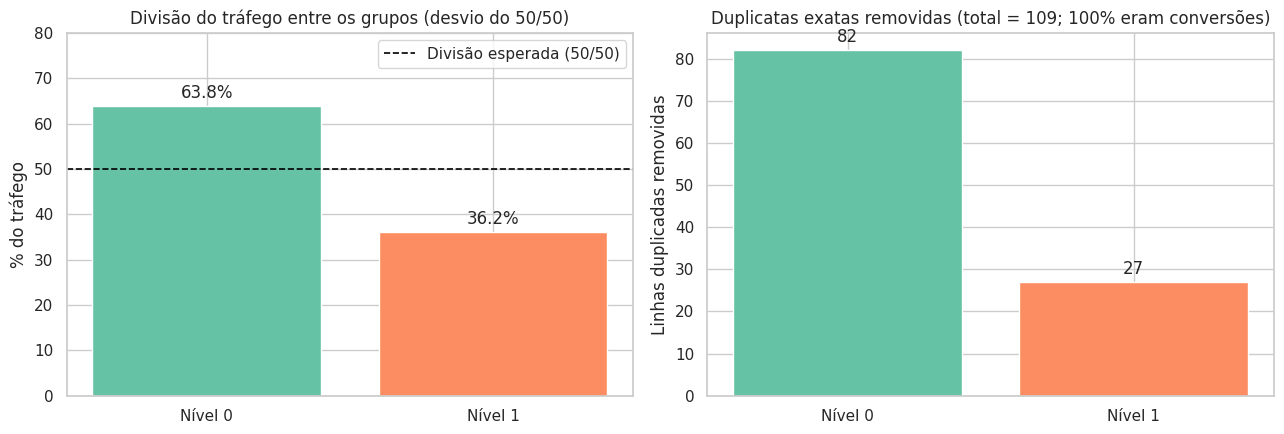

In [ ]:
PALETA_CORES_POR_GRUPO = dict(zip((GRUPO_NIVEL_0, GRUPO_NIVEL_1), sns.color_palette('Set2')[:2]))


def plotar_auditoria(base_bruta, base_sem_duplicatas, resumo_duplicatas):
    """Divisão do tráfego vs 50/50 (SRM) e onde estavam as duplicatas removidas."""
    figura, (eixo_srm, eixo_dup) = plt.subplots(1, 2, figsize=(13, 4.5))

    pct_por_grupo = base_sem_duplicatas['group'].value_counts(normalize=True).reindex(
        [GRUPO_NIVEL_0, GRUPO_NIVEL_1]) * 100
    barras = eixo_srm.bar(pct_por_grupo.index, pct_por_grupo.values,
                          color=[PALETA_CORES_POR_GRUPO[g] for g in pct_por_grupo.index])
    eixo_srm.axhline(50, color='black', linestyle='--', linewidth=1.2, label='Divisão esperada (50/50)')
    eixo_srm.bar_label(barras, fmt='%.1f%%', padding=3)
    eixo_srm.set_ylim(0, 80)
    eixo_srm.set_ylabel('% do tráfego')
    eixo_srm.set_title('Divisão do tráfego entre os grupos (desvio do 50/50)')
    eixo_srm.legend()

    por_grupo = pd.Series(resumo_duplicatas['por_grupo']).reindex([GRUPO_NIVEL_0, GRUPO_NIVEL_1]).fillna(0)
    barras = eixo_dup.bar(por_grupo.index, por_grupo.values,
                          color=[PALETA_CORES_POR_GRUPO[g] for g in por_grupo.index])
    eixo_dup.bar_label(barras, fmt='%d', padding=3)
    eixo_dup.set_ylabel('Linhas duplicadas removidas')
    eixo_dup.set_title(f"Duplicatas exatas removidas (total = {resumo_duplicatas['removidas']}; "
                       f"{formatar_numero(resumo_duplicatas['pct_conversoes_entre_removidas'], 0)}% eram conversões)")
    plt.tight_layout()
    plt.show()


plotar_auditoria(base_bruta, base_sem_duplicatas, resumo_duplicatas)

## 2. Q1 – Qual configuração do menu lateral levou mais usuários a acessarem a página específica?

In [ ]:
def calcular_acessos(base_sem_duplicatas: pd.DataFrame) -> pd.DataFrame:
    """
    Q1: 'acessar a página' = converted == 1 (conversão para a página de interesse).
    O tráfego total mede apenas a alocação do teste, não o efeito do menu.
    """
    tabela_acessos = base_sem_duplicatas.groupby('group').agg(
        Trafego_Total=('user_id', 'size'), Acessos_Pagina=('converted', 'sum'))
    tabela_acessos['Pct_do_Trafego'] = (
        tabela_acessos['Trafego_Total'] / tabela_acessos['Trafego_Total'].sum() * 100).round(1)
    return tabela_acessos

In [ ]:
print('--- Q1: Acessos à página de interesse ---')
tabela_acessos = calcular_acessos(base_sem_duplicatas)
tabela_acessos

--- Q1: Acessos à página de interesse ---


,Trafego_Total,Acessos_Pagina,Pct_do_Trafego
group,,,
Nível 0,1402,588,63.8
Nível 1,794,112,36.2


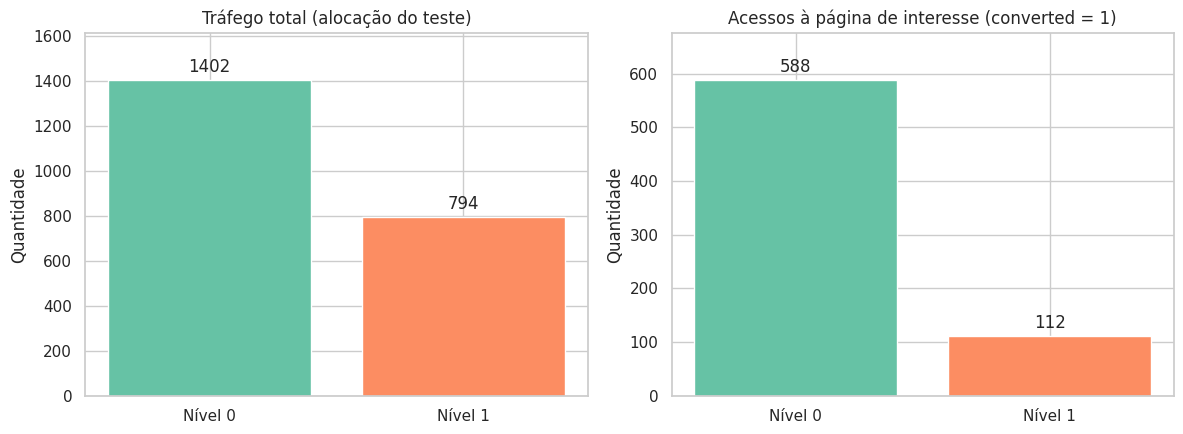

In [ ]:
def plotar_acessos(tabela_acessos: pd.DataFrame):
    """Q1 (visual): tráfego recebido x acessos à página, por grupo."""
    figura, (eixo_trafego, eixo_acessos) = plt.subplots(1, 2, figsize=(12, 4.5))
    cores = [PALETA_CORES_POR_GRUPO[g] for g in tabela_acessos.index]
    for eixo, coluna, titulo in ((eixo_trafego, 'Trafego_Total', 'Tráfego total (alocação do teste)'),
                                 (eixo_acessos, 'Acessos_Pagina', 'Acessos à página de interesse (converted = 1)')):
        barras = eixo.bar(tabela_acessos.index, tabela_acessos[coluna], color=cores)
        eixo.bar_label(barras, fmt='%d', padding=3)
        eixo.set_title(titulo)
        eixo.set_ylabel('Quantidade')
        eixo.set_ylim(0, tabela_acessos[coluna].max() * 1.15)
    plt.tight_layout()
    plt.show()


plotar_acessos(tabela_acessos)

## 3. Q2 – Qual o tempo médio de sessão para cada configuração do menu?

In [ ]:
def calcular_estatisticas_tempo(base_sem_duplicatas: pd.DataFrame) -> pd.DataFrame:
    """
    Q2: duas visões do tempo na página de interesse.
      - Quem chegou: só session_duration > 0. Zero = não chegou à página.
      - Por acesso: zeros incluídos. Sem seleção, mistura 'chegar' e 'ficar'.
    Nulos (convertidos sem duração medida) são dado faltante e saem dos dois cálculos.
    """
    base_com_duracao = base_sem_duplicatas.dropna(subset=['session_duration'])
    base_quem_chegou = base_com_duracao[base_com_duracao['session_duration'] > 0]

    duracao_quem_chegou = base_quem_chegou.groupby('group')['session_duration']
    tabela_tempo = pd.DataFrame({
        'N_Acessos': base_com_duracao.groupby('group').size(),
        'N_Chegaram (session_duration > 0)': base_quem_chegou.groupby('group').size(),
        'Media_Quem_Chegou': duracao_quem_chegou.mean(),
        'Mediana_Quem_Chegou': duracao_quem_chegou.median(),
        'Desvio_Quem_Chegou': duracao_quem_chegou.std(),
        'Media_Por_Acesso': base_com_duracao.groupby('group')['session_duration'].mean(),
    })
    tabela_tempo.insert(2, 'Pct_Chegaram', tabela_tempo['N_Chegaram (session_duration > 0)'] / tabela_tempo['N_Acessos'] * 100)
    return tabela_tempo.round(2)


def calcular_ic_diferenca_medias_welch(amostra_nivel_0: pd.Series, amostra_nivel_1: pd.Series,
                                       nivel_confianca: float = 0.95):
    """IC da diferença de médias (Welch). Independe da versão do scipy."""
    variancia_media_nivel_0 = amostra_nivel_0.var(ddof=1) / len(amostra_nivel_0)
    variancia_media_nivel_1 = amostra_nivel_1.var(ddof=1) / len(amostra_nivel_1)
    variancia_total = variancia_media_nivel_0 + variancia_media_nivel_1
    graus_liberdade = variancia_total ** 2 / (
        variancia_media_nivel_0 ** 2 / (len(amostra_nivel_0) - 1)
        + variancia_media_nivel_1 ** 2 / (len(amostra_nivel_1) - 1))
    margem_erro = stats.t.ppf(1 - (1 - nivel_confianca) / 2, graus_liberdade) * np.sqrt(variancia_total)
    diferenca_medias = amostra_nivel_0.mean() - amostra_nivel_1.mean()
    return diferenca_medias - margem_erro, diferenca_medias + margem_erro


def testar_tempo_sessao(base_sem_duplicatas: pd.DataFrame) -> pd.DataFrame:
    """
    Teste da diferença de tempo entre grupos (Nível 0 - Nível 1).
    Welch (não assume variâncias iguais) + Mann-Whitney (robusto à assimetria; a duração
    é assimétrica e tem mais de um 'bloco' de valores, então a média sozinha engana).
    """
    base_com_duracao = base_sem_duplicatas.dropna(subset=['session_duration'])
    bases_por_visao = {
        'Quem chegou à página': base_com_duracao[base_com_duracao['session_duration'] > 0],
        'Por acesso (zeros incluídos)': base_com_duracao,
    }
    resultados_por_visao = {}
    for nome_visao, base_visao in bases_por_visao.items():
        duracao_nivel_0 = base_visao.loc[base_visao['group'] == GRUPO_NIVEL_0, 'session_duration']
        duracao_nivel_1 = base_visao.loc[base_visao['group'] == GRUPO_NIVEL_1, 'session_duration']
        ic_diferenca = calcular_ic_diferenca_medias_welch(duracao_nivel_0, duracao_nivel_1)
        resultados_por_visao[nome_visao] = {
            'Dif_Media_s': duracao_nivel_0.mean() - duracao_nivel_1.mean(),
            'IC95_inf': ic_diferenca[0],
            'IC95_sup': ic_diferenca[1],
            'p_Welch': stats.ttest_ind(duracao_nivel_0, duracao_nivel_1, equal_var=False).pvalue,
            'p_MannWhitney': stats.mannwhitneyu(duracao_nivel_0, duracao_nivel_1).pvalue,
        }
    return pd.DataFrame(resultados_por_visao).T

In [ ]:
print('--- Q2: Tempo de sessão (segundos) ---')
tabela_tempo = calcular_estatisticas_tempo(base_sem_duplicatas)
display(tabela_tempo.T)
testes_tempo = testar_tempo_sessao(base_sem_duplicatas)
print('\nDiferença Nível 0 - Nível 1 (segundos):')
display(formatar_colunas_p_valor(testes_tempo.round(2), ['p_Welch', 'p_MannWhitney']))

--- Q2: Tempo de sessão (segundos) ---


group,Nível 0,Nível 1
N_Acessos,1383.00,790.00
N_Chegaram (session_duration > 0),569.00,108.00
Pct_Chegaram,41.14,13.67
Media_Quem_Chegou,19.13,11.24
Mediana_Quem_Chegou,18.62,12.36
Desvio_Quem_Chegou,16.76,9.39
Media_Por_Acesso,7.87,1.54



Diferença Nível 0 - Nível 1 (segundos):


,Dif_Media_s,IC95_inf,IC95_sup,p_Welch,p_MannWhitney
Quem chegou à página,7.89,5.64,10.15,"< 0,001","< 0,001"
Por acesso (zeros incluídos),6.33,5.50,7.17,"< 0,001","< 0,001"


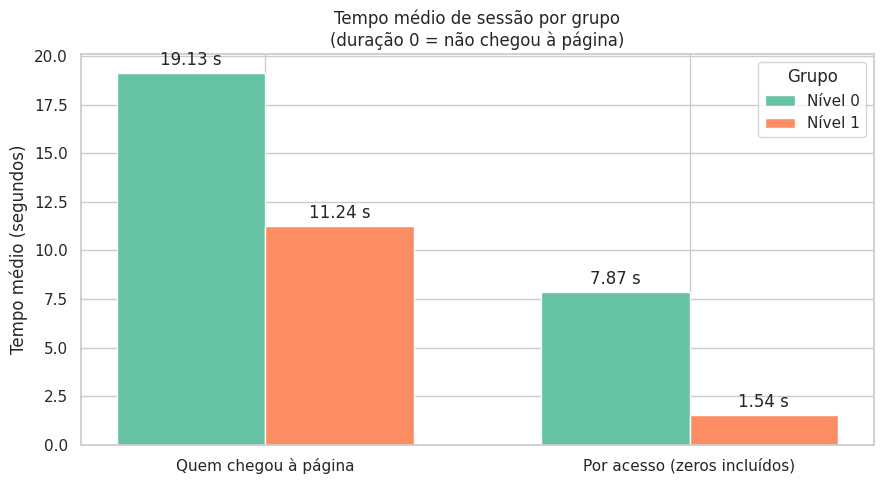

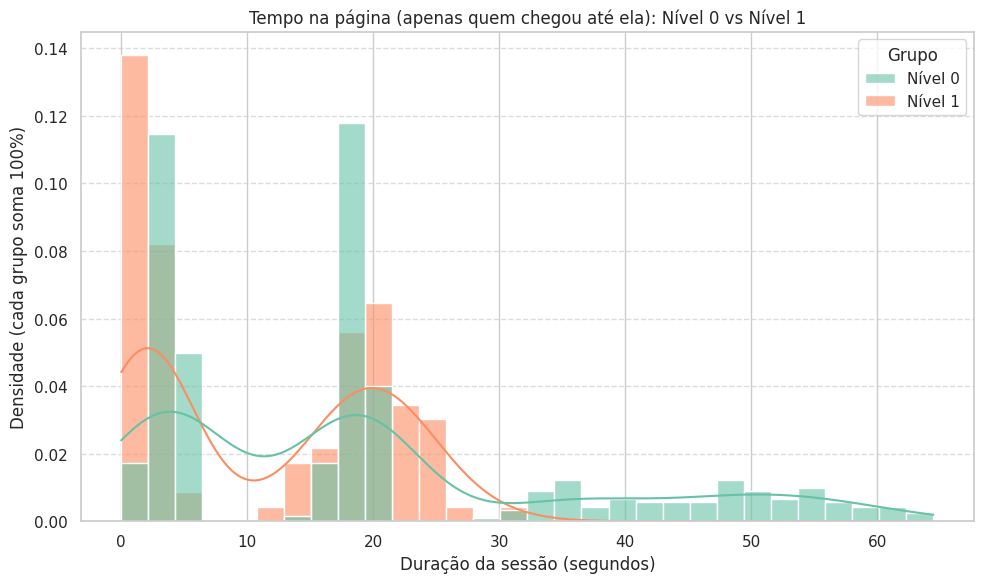

In [ ]:
def plotar_distribuicao_sessao(base_sem_duplicatas: pd.DataFrame):
    """Q2 (visual): distribuição do tempo na página, somente de quem chegou até ela."""
    base_quem_chegou = base_sem_duplicatas[base_sem_duplicatas['session_duration'] > 0]
    plt.figure(figsize=(10, 6))
    sns.histplot(data=base_quem_chegou, x='session_duration', hue='group', kde=True, bins=30,
                 stat='density', common_norm=False, palette=PALETA_CORES_POR_GRUPO, alpha=0.6)
    plt.gca().get_legend().set_title('Grupo')
    plt.title('Tempo na página (apenas quem chegou até ela): Nível 0 vs Nível 1')
    plt.xlabel('Duração da sessão (segundos)')
    plt.ylabel('Densidade (cada grupo soma 100%)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


def plotar_medias_tempo(tabela_tempo: pd.DataFrame):
    """Q2 (visual): as duas visões do tempo médio, lado a lado."""
    figura, eixo = plt.subplots(figsize=(9, 5))
    colunas = {'Media_Quem_Chegou': 'Quem chegou à página', 'Media_Por_Acesso': 'Por acesso (zeros incluídos)'}
    posicoes = np.arange(len(colunas))
    largura = 0.35
    for deslocamento, grupo in zip((-largura / 2, largura / 2), (GRUPO_NIVEL_0, GRUPO_NIVEL_1)):
        valores = [tabela_tempo.loc[grupo, coluna] for coluna in colunas]
        barras = eixo.bar(posicoes + deslocamento, valores, largura, label=grupo,
                          color=PALETA_CORES_POR_GRUPO[grupo])
        eixo.bar_label(barras, fmt='%.2f s', padding=3)
    eixo.set_xticks(posicoes)
    eixo.set_xticklabels(colunas.values())
    eixo.set_ylabel('Tempo médio (segundos)')
    eixo.set_title('Tempo médio de sessão por grupo\n(duração 0 = não chegou à página)')
    eixo.legend(title='Grupo')
    plt.tight_layout()
    plt.show()


plotar_medias_tempo(tabela_tempo)
plotar_distribuicao_sessao(base_sem_duplicatas)

## 4. Q3 – Qual é a taxa de conversão para cada configuração do menu?

In [ ]:
def calcular_taxa_conversao(base_sem_duplicatas: pd.DataFrame) -> pd.DataFrame:
    """Q3: taxa de conversão (%) por grupo, com IC 95% de Wilson (bom para proporções)."""
    tabela_conversao = base_sem_duplicatas.groupby('group')['converted'].agg(N='size', Conversoes='sum')
    tabela_conversao['Taxa_Pct'] = tabela_conversao['Conversoes'] / tabela_conversao['N'] * 100
    ics_wilson = [proportion_confint(conversoes, total_acessos, method='wilson')
                  for conversoes, total_acessos in zip(tabela_conversao['Conversoes'], tabela_conversao['N'])]
    tabela_conversao['IC95_inf'] = [intervalo[0] * 100 for intervalo in ics_wilson]
    tabela_conversao['IC95_sup'] = [intervalo[1] * 100 for intervalo in ics_wilson]
    return tabela_conversao.round(2)

In [ ]:
print('--- Q3: Conversão (%) ---')
tabela_conversao = calcular_taxa_conversao(base_sem_duplicatas)
tabela_conversao

--- Q3: Conversão (%) ---


,N,Conversoes,Taxa_Pct,IC95_inf,IC95_sup
group,,,,,
Nível 0,1402,588,41.94,39.38,44.54
Nível 1,794,112,14.11,11.86,16.70


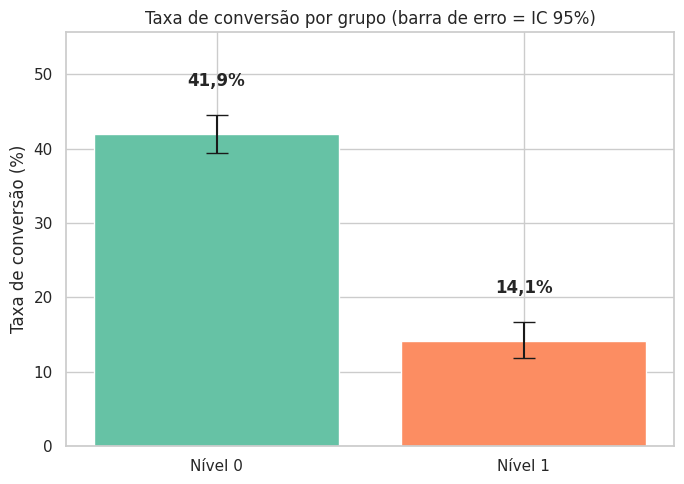

In [ ]:
def plotar_taxa_conversao(tabela_conversao: pd.DataFrame):
    """Q3 (visual): taxa de conversão por grupo com IC 95% de Wilson."""
    figura, eixo = plt.subplots(figsize=(7, 5))
    grupos = list(tabela_conversao.index)
    taxas = tabela_conversao['Taxa_Pct'].values
    erros = [taxas - tabela_conversao['IC95_inf'].values, tabela_conversao['IC95_sup'].values - taxas]
    barras = eixo.bar(grupos, taxas, yerr=erros, capsize=8,
                      color=[PALETA_CORES_POR_GRUPO[g] for g in grupos])
    eixo.bar_label(barras, labels=[f'{t:.1f}%'.replace('.', ',') for t in taxas], padding=18, fontweight='bold')
    eixo.set_ylabel('Taxa de conversão (%)')
    eixo.set_ylim(0, max(tabela_conversao['IC95_sup']) * 1.25)
    eixo.set_title('Taxa de conversão por grupo (barra de erro = IC 95%)')
    plt.tight_layout()
    plt.show()


plotar_taxa_conversao(tabela_conversao)

## 5. Q4 – A diferença nos acessos entre as configurações é estatisticamente significativa?

In [ ]:
def testar_significancia_conversao(base: pd.DataFrame) -> dict:
    """
    Q4: qui-quadrado de independência (grupo x converteu) + tamanho do efeito.
    Em tabela 2x2 o scipy aplica a correção de Yates por padrão.
    O p-valor diz se a diferença existe; a diferença em p.p. e o IC dizem o quanto importa.
    """
    tabela_contingencia = pd.crosstab(base['group'], base['converted'])
    qui_quadrado, p_valor, _, _ = chi2_contingency(tabela_contingencia)

    conversao_nivel_0 = base.loc[base['group'] == GRUPO_NIVEL_0, 'converted']
    conversao_nivel_1 = base.loc[base['group'] == GRUPO_NIVEL_1, 'converted']
    taxa_nivel_0, taxa_nivel_1 = conversao_nivel_0.mean(), conversao_nivel_1.mean()

    diferenca_taxas = taxa_nivel_0 - taxa_nivel_1
    erro_padrao_diferenca = np.sqrt(taxa_nivel_0 * (1 - taxa_nivel_0) / len(conversao_nivel_0)
                                    + taxa_nivel_1 * (1 - taxa_nivel_1) / len(conversao_nivel_1))
    return {
        'taxa_nivel_0': taxa_nivel_0 * 100,
        'taxa_nivel_1': taxa_nivel_1 * 100,
        'diferenca_pp': diferenca_taxas * 100,
        'ic95_inferior_pp': (diferenca_taxas - 1.96 * erro_padrao_diferenca) * 100,
        'ic95_superior_pp': (diferenca_taxas + 1.96 * erro_padrao_diferenca) * 100,
        'lift_relativo_pct': (taxa_nivel_0 / taxa_nivel_1 - 1) * 100,
        'odds_ratio': (taxa_nivel_0 / (1 - taxa_nivel_0)) / (taxa_nivel_1 / (1 - taxa_nivel_1)),
        'qui_quadrado': qui_quadrado,
        'p_valor': p_valor,
        'significativo': p_valor < NIVEL_SIGNIFICANCIA,
    }


def testar_robustez(base_bruta: pd.DataFrame, base_sem_duplicatas: pd.DataFrame):
    """
    A conclusão depende de duplicatas ou do user_id? Refaz o teste em quatro cenários
    e estima o odds ratio ajustado por hora, dispositivo e país (regressão logística).
    """
    base_primeira_visita = base_sem_duplicatas.sort_values('timestamp').drop_duplicates('user_id')
    grupos_por_user_id = base_sem_duplicatas.groupby('user_id')['group'].transform('nunique')
    base_ids_em_um_grupo = base_sem_duplicatas[grupos_por_user_id == 1]

    bases_por_cenario = {
        'Base bruta (com duplicatas)': base_bruta,
        'Base sem duplicatas (principal)': base_sem_duplicatas,
        '1ª visita de cada user_id': base_primeira_visita,
        'Só user_id vistos em um grupo': base_ids_em_um_grupo,
    }
    linhas_tabela = []
    for nome_cenario, base_cenario in bases_por_cenario.items():
        resultado_cenario = testar_significancia_conversao(base_cenario)
        linhas_tabela.append({
            'Cenario': nome_cenario,
            'N_N0': (base_cenario['group'] == GRUPO_NIVEL_0).sum(),
            'N_N1': (base_cenario['group'] == GRUPO_NIVEL_1).sum(),
            'Conv_N0_Pct': resultado_cenario['taxa_nivel_0'],
            'Conv_N1_Pct': resultado_cenario['taxa_nivel_1'],
            'Dif_pp': resultado_cenario['diferenca_pp'],
            'P_valor': resultado_cenario['p_valor'],
        })
    tabela_robustez = pd.DataFrame(linhas_tabela).set_index('Cenario').round(2)

    base_com_indicador_nivel_1 = base_sem_duplicatas.assign(
        nivel_1=(base_sem_duplicatas['group'] == GRUPO_NIVEL_1).astype(int))

    def estimar_odds_ratio_nivel_0(formula_modelo: str) -> dict:
        modelo_logistico = smf.logit(formula_modelo, base_com_indicador_nivel_1).fit(disp=0)
        ic_coeficiente = modelo_logistico.conf_int().loc['nivel_1']
        # O coeficiente compara Nível 1 com Nível 0. Invertemos o sinal para expressar Nível 0 vs Nível 1.
        return {
            'odds_ratio': np.exp(-modelo_logistico.params['nivel_1']),
            'ic95_inferior': np.exp(-ic_coeficiente[1]),
            'ic95_superior': np.exp(-ic_coeficiente[0]),
        }

    odds_ratios = {
        'bruto': estimar_odds_ratio_nivel_0('converted ~ nivel_1'),
        'ajustado': estimar_odds_ratio_nivel_0('converted ~ nivel_1 + C(device) + C(country) + C(hour)'),
    }
    return tabela_robustez, odds_ratios

In [ ]:
print('--- Q4: Teste estatístico (conversão) ---')
resultado_conversao = testar_significancia_conversao(base_sem_duplicatas)
print('H0: as taxas de conversão são iguais entre os grupos.')
print(f"Chi2 = {formatar_numero(resultado_conversao['qui_quadrado'], 2)} | "
      f"p = {resultado_conversao['p_valor']:.2e} | "
      f"{'diferença significativa (rejeita H0)' if resultado_conversao['significativo'] else 'sem evidência de diferença'}")
print(f"Diferença = {formatar_numero(resultado_conversao['diferenca_pp'])} p.p. "
      f"(IC 95%: {formatar_numero(resultado_conversao['ic95_inferior_pp'])} a "
      f"{formatar_numero(resultado_conversao['ic95_superior_pp'])}) "
      f"| odds ratio = {formatar_numero(resultado_conversao['odds_ratio'], 2)}")
print('\nRobustez:')
tabela_robustez, odds_ratios = testar_robustez(base_bruta, base_sem_duplicatas)
display(formatar_colunas_p_valor(tabela_robustez, ['P_valor']))
print(f"Odds ratio Nível 0 vs Nível 1: bruto = {formatar_numero(odds_ratios['bruto']['odds_ratio'], 2)} "
      f"| ajustado por hora, dispositivo e país = {formatar_numero(odds_ratios['ajustado']['odds_ratio'], 2)} "
      f"(IC 95%: {formatar_numero(odds_ratios['ajustado']['ic95_inferior'], 2)} a "
      f"{formatar_numero(odds_ratios['ajustado']['ic95_superior'], 2)})")

--- Q4: Teste estatístico (conversão) ---
H0: as taxas de conversão são iguais entre os grupos.
Chi2 = 179,58 | p = 6.00e-41 | diferença significativa (rejeita H0)
Diferença = 27,8 p.p. (IC 95%: 24,3 a 31,4) | odds ratio = 4,40

Robustez:


,N_N0,N_N1,Conv_N0_Pct,Conv_N1_Pct,Dif_pp,P_valor
Cenario,,,,,,
Base bruta (com duplicatas),1484,821,45.15,16.93,28.22,"< 0,001"
Base sem duplicatas (principal),1402,794,41.94,14.11,27.83,"< 0,001"
1ª visita de cada user_id,816,479,38.60,13.78,24.82,"< 0,001"
Só user_id vistos em um grupo,936,367,41.88,14.71,27.17,"< 0,001"


Odds ratio Nível 0 vs Nível 1: bruto = 4,40 | ajustado por hora, dispositivo e país = 4,46 (IC 95%: 3,53 a 5,63)


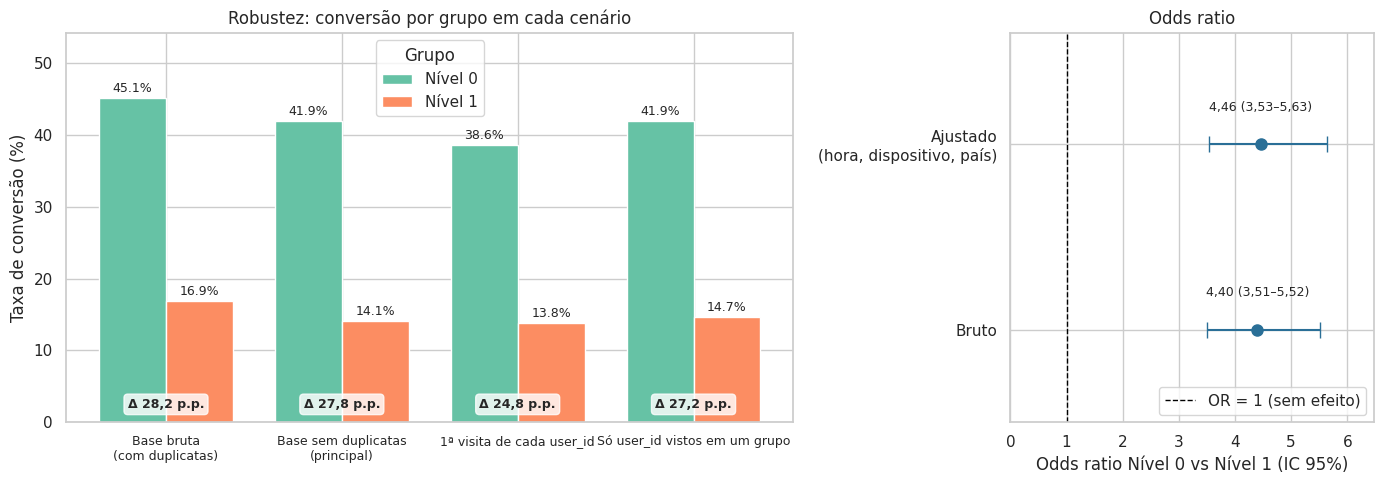

In [ ]:
def plotar_robustez(tabela_robustez: pd.DataFrame, resultado_conversao: dict, odds_ratios: dict):
    """Q4 (visual): a diferença se mantém em todos os cenários? + odds ratio bruto x ajustado."""
    figura, (eixo_cenarios, eixo_or) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})

    cenarios = list(tabela_robustez.index)
    posicoes = np.arange(len(cenarios))
    largura = 0.38
    for deslocamento, grupo, coluna in ((-largura / 2, GRUPO_NIVEL_0, 'Conv_N0_Pct'),
                                        (largura / 2, GRUPO_NIVEL_1, 'Conv_N1_Pct')):
        barras = eixo_cenarios.bar(posicoes + deslocamento, tabela_robustez[coluna], largura,
                                   label=grupo, color=PALETA_CORES_POR_GRUPO[grupo])
        eixo_cenarios.bar_label(barras, fmt='%.1f%%', padding=2, fontsize=9)
    for posicao, dif in zip(posicoes, tabela_robustez['Dif_pp']):
        eixo_cenarios.text(posicao, 2, f'Δ {dif:.1f}'.replace('.', ',') + ' p.p.', ha='center',
                           fontsize=9, fontweight='bold', bbox=dict(boxstyle='round', fc='white', alpha=0.8))
    eixo_cenarios.set_xticks(posicoes)
    eixo_cenarios.set_xticklabels([c.replace(' (', '\n(') for c in cenarios], fontsize=9)
    eixo_cenarios.set_ylabel('Taxa de conversão (%)')
    eixo_cenarios.set_ylim(0, tabela_robustez['Conv_N0_Pct'].max() * 1.2)
    eixo_cenarios.set_title('Robustez: conversão por grupo em cada cenário')
    eixo_cenarios.legend(title='Grupo')

    rotulos, centros, inferiores, superiores = [], [], [], []
    for nome, rotulo in (('bruto', 'Bruto'), ('ajustado', 'Ajustado\n(hora, dispositivo, país)')):
        rotulos.append(rotulo)
        centros.append(odds_ratios[nome]['odds_ratio'])
        inferiores.append(odds_ratios[nome]['ic95_inferior'])
        superiores.append(odds_ratios[nome]['ic95_superior'])
    centros, inferiores, superiores = map(np.array, (centros, inferiores, superiores))
    eixo_or.errorbar(centros, range(len(rotulos)), xerr=[centros - inferiores, superiores - centros],
                     fmt='o', color='#2a6f97', capsize=6, markersize=8)
    eixo_or.axvline(1, color='black', linestyle='--', linewidth=1, label='OR = 1 (sem efeito)')
    for i, (c, lo, hi) in enumerate(zip(centros, inferiores, superiores)):
        eixo_or.text(c, i + 0.18, f'{c:.2f} ({lo:.2f}–{hi:.2f})'.replace('.', ','), ha='center', fontsize=9)
    eixo_or.set_yticks(range(len(rotulos)))
    eixo_or.set_yticklabels(rotulos)
    eixo_or.set_ylim(-0.5, len(rotulos) - 0.4)
    eixo_or.set_xlim(0, max(superiores) * 1.15)
    eixo_or.set_xlabel('Odds ratio Nível 0 vs Nível 1 (IC 95%)')
    eixo_or.set_title('Odds ratio')
    eixo_or.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


plotar_robustez(tabela_robustez, resultado_conversao, odds_ratios)

## 6. Análise por dispositivo e por país

In [ ]:
def analisar_por_segmento(base_sem_duplicatas: pd.DataFrame, coluna_segmento: str):
    """
    Conversão por segmento x grupo, com:
      - Fisher por segmento (efeito do menu dentro do segmento);
      - qui-quadrado entre segmentos DENTRO de cada grupo (segmentos diferem entre si?);
      - teste de interação grupo x segmento (o efeito do menu muda conforme o segmento?).
    """
    linhas_tabela = []
    for nome_segmento, base_segmento in base_sem_duplicatas.groupby(coluna_segmento):
        conversao_nivel_0 = base_segmento.loc[base_segmento['group'] == GRUPO_NIVEL_0, 'converted']
        conversao_nivel_1 = base_segmento.loc[base_segmento['group'] == GRUPO_NIVEL_1, 'converted']
        _, p_valor_fisher = stats.fisher_exact([
            [conversao_nivel_0.sum(), len(conversao_nivel_0) - conversao_nivel_0.sum()],
            [conversao_nivel_1.sum(), len(conversao_nivel_1) - conversao_nivel_1.sum()]])
        linhas_tabela.append({
            coluna_segmento: nome_segmento,
            'Acessos_N0': len(conversao_nivel_0),
            'Conv_N0_Pct': conversao_nivel_0.mean() * 100,
            'Acessos_N1': len(conversao_nivel_1),
            'Conversoes_N1': int(conversao_nivel_1.sum()),
            'Conv_N1_Pct': conversao_nivel_1.mean() * 100,
            'Dif_pp': (conversao_nivel_0.mean() - conversao_nivel_1.mean()) * 100,
            'p_Fisher': p_valor_fisher,
        })
    tabela_segmentos = pd.DataFrame(linhas_tabela)

    resultados_testes = {}
    for grupo in (GRUPO_NIVEL_0, GRUPO_NIVEL_1):
        base_grupo = base_sem_duplicatas[base_sem_duplicatas['group'] == grupo]
        resultados_testes[f'p_entre_segmentos_{grupo}'] = chi2_contingency(
            pd.crosstab(base_grupo[coluna_segmento], base_grupo['converted']))[1]

    base_com_indicador_nivel_1 = base_sem_duplicatas.assign(
        nivel_1=(base_sem_duplicatas['group'] == GRUPO_NIVEL_1).astype(int))
    modelo_sem_interacao = smf.logit(
        f'converted ~ nivel_1 + C({coluna_segmento})', base_com_indicador_nivel_1).fit(disp=0)
    modelo_com_interacao = smf.logit(
        f'converted ~ nivel_1 * C({coluna_segmento})', base_com_indicador_nivel_1).fit(disp=0)
    estatistica_razao_verossimilhanca = 2 * (modelo_com_interacao.llf - modelo_sem_interacao.llf)
    graus_liberdade_interacao = modelo_com_interacao.df_model - modelo_sem_interacao.df_model
    resultados_testes['p_interacao'] = stats.chi2.sf(estatistica_razao_verossimilhanca, graus_liberdade_interacao)

    resultados_testes['qtd_segmentos_nivel_0_maior'] = int((tabela_segmentos['Dif_pp'] > 0).sum())
    resultados_testes['qtd_segmentos'] = len(tabela_segmentos)
    return tabela_segmentos, resultados_testes


def avaliar_segmento_critico(base_sem_duplicatas: pd.DataFrame, tabela_segmentos: pd.DataFrame,
                             coluna_segmento: str) -> dict:
    """
    Segmento com pior conversão no Nível 1 vs. os demais. Como ele foi escolhido DEPOIS de
    olhar os dados, o p-valor recebe correção de Bonferroni (multiplica pelo nº de segmentos).
    """
    segmento_critico = tabela_segmentos.loc[tabela_segmentos['Conv_N1_Pct'].idxmin(), coluna_segmento]
    base_nivel_1 = base_sem_duplicatas[base_sem_duplicatas['group'] == GRUPO_NIVEL_1]
    conversao_segmento_critico = base_nivel_1.loc[base_nivel_1[coluna_segmento] == segmento_critico, 'converted']
    conversao_demais_segmentos = base_nivel_1.loc[base_nivel_1[coluna_segmento] != segmento_critico, 'converted']

    _, p_valor_fisher = stats.fisher_exact([
        [conversao_segmento_critico.sum(), len(conversao_segmento_critico) - conversao_segmento_critico.sum()],
        [conversao_demais_segmentos.sum(), len(conversao_demais_segmentos) - conversao_demais_segmentos.sum()]])
    ic_wilson = proportion_confint(conversao_segmento_critico.sum(), len(conversao_segmento_critico),
                                   method='wilson')
    return {
        'segmento': segmento_critico,
        'conversoes': int(conversao_segmento_critico.sum()),
        'total_acessos': len(conversao_segmento_critico),
        'taxa_segmento': conversao_segmento_critico.mean() * 100,
        'taxa_demais_segmentos': conversao_demais_segmentos.mean() * 100,
        'ic95_inferior': ic_wilson[0] * 100,
        'ic95_superior': ic_wilson[1] * 100,
        'p_valor_bonferroni': min(1.0, p_valor_fisher * len(tabela_segmentos)),
    }

In [ ]:
def plotar_conversao_por_segmento(base: pd.DataFrame, tabela_segmentos: pd.DataFrame, coluna_segmento: str,
                                  titulo_segmento: str, horizontal: bool = False):
    """
    Visual da análise por segmento, em dois painéis:
      - esquerda: taxa de conversão por segmento e grupo, com IC 95% de Wilson;
      - direita: diferença Nível 0 - Nível 1 (p.p.) em cada segmento.
    """
    segmentos = list(tabela_segmentos[coluna_segmento])
    figura, (eixo_taxas, eixo_dif) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})

    posicoes = np.arange(len(segmentos))
    largura = 0.38
    for deslocamento, grupo in ((-largura / 2, GRUPO_NIVEL_0), (largura / 2, GRUPO_NIVEL_1)):
        taxas, inferiores, superiores = [], [], []
        for segmento in segmentos:
            conversao = base.loc[(base['group'] == grupo) & (base[coluna_segmento] == segmento), 'converted']
            ic = proportion_confint(conversao.sum(), len(conversao), method='wilson')
            taxas.append(conversao.mean() * 100)
            inferiores.append(ic[0] * 100)
            superiores.append(ic[1] * 100)
        taxas, inferiores, superiores = map(np.array, (taxas, inferiores, superiores))
        barras = eixo_taxas.bar(posicoes + deslocamento, taxas, largura, label=grupo,
                                yerr=[taxas - inferiores, superiores - taxas], capsize=3,
                                color=PALETA_CORES_POR_GRUPO[grupo], error_kw={'alpha': 0.7})
        eixo_taxas.bar_label(barras, labels=[f'{t:.0f}%' for t in taxas], padding=14, fontsize=9)
    eixo_taxas.set_xticks(posicoes)
    eixo_taxas.set_xticklabels(segmentos, rotation=0 if len(segmentos) <= 3 else 25)
    eixo_taxas.set_ylabel('Taxa de conversão (%)')
    eixo_taxas.set_ylim(0, 75)
    eixo_taxas.set_title(f'Taxa de conversão por {titulo_segmento} e grupo (barra de erro = IC 95%)')
    eixo_taxas.legend(title='Grupo')

    dif = tabela_segmentos['Dif_pp'].values
    barras = eixo_dif.barh(segmentos, dif, color='#2a6f97')
    eixo_dif.bar_label(barras, labels=[f'{d:.1f}'.replace('.', ',') + ' p.p.' for d in dif], padding=3, fontsize=9)
    eixo_dif.axvline(0, color='black', linewidth=1)
    eixo_dif.invert_yaxis()
    eixo_dif.set_xlim(0, max(dif) * 1.25)
    eixo_dif.set_xlabel('Nível 0 − Nível 1 (p.p.)')
    eixo_dif.set_title('Vantagem do Nível 0 em cada segmento')
    plt.tight_layout()
    plt.show()

--- Análise por dispositivo ---


,device,Acessos_N0,Conv_N0_Pct,Acessos_N1,Conversoes_N1,Conv_N1_Pct,Dif_pp,p_Fisher
0,Desktop,461,41.21,295,37,12.54,28.67,"< 0,001"
1,Smartphone,460,44.13,240,40,16.67,27.46,"< 0,001"
2,Tablet,481,40.54,259,35,13.51,27.03,"< 0,001"


  p_entre_segmentos_Nível 0: p 0,498
  p_entre_segmentos_Nível 1: p 0,374
  p_interacao: p 0,748


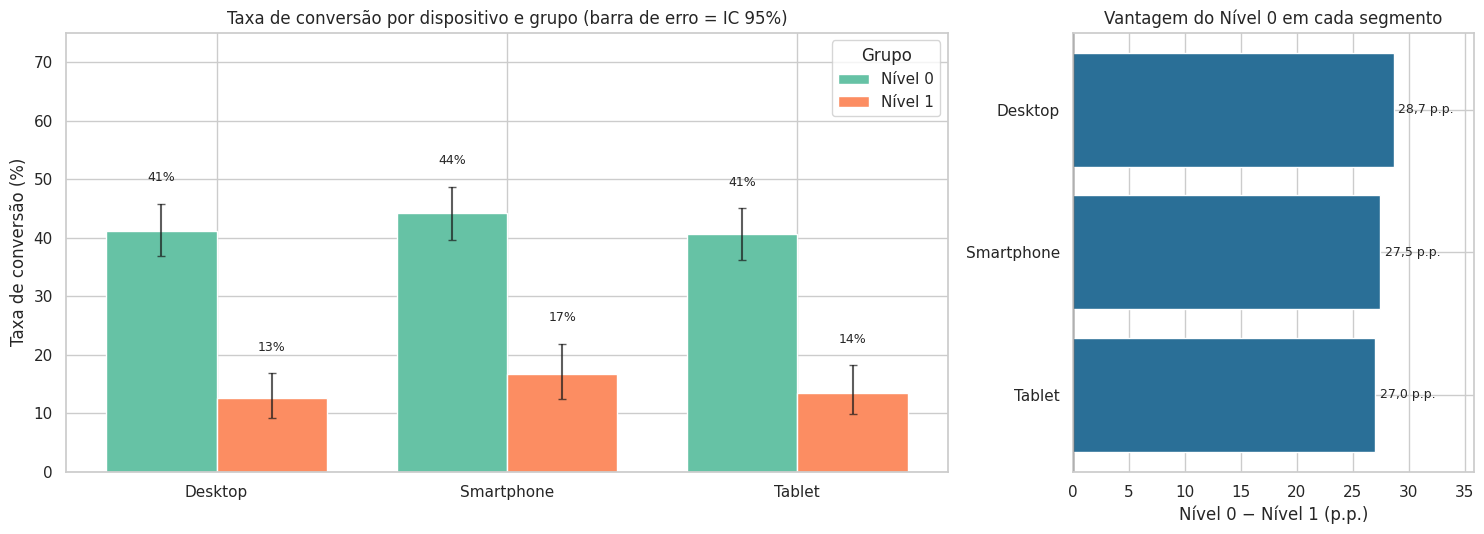

In [ ]:
print('--- Análise por dispositivo ---')
tabela_dispositivos, testes_dispositivo = analisar_por_segmento(base_sem_duplicatas, 'device')
display(formatar_colunas_p_valor(tabela_dispositivos.round(2), ['p_Fisher']))
imprimir_p_valores(testes_dispositivo)
plotar_conversao_por_segmento(base_sem_duplicatas, tabela_dispositivos, 'device', 'dispositivo')

--- Análise por país ---


,country,Acessos_N0,Conv_N0_Pct,Acessos_N1,Conversoes_N1,Conv_N1_Pct,Dif_pp,p_Fisher
0,Alemanha,187,43.85,84,3,3.57,40.28,"< 0,001"
1,Austrália,161,38.51,113,12,10.62,27.89,"< 0,001"
2,Brasil,194,38.14,104,16,15.38,22.76,"< 0,001"
3,Canadá,156,44.23,109,19,17.43,26.80,"< 0,001"
4,EUA,166,46.39,95,18,18.95,27.44,"< 0,001"
5,França,176,38.64,86,12,13.95,24.68,"< 0,001"
6,Reino Unido,190,40.53,108,16,14.81,25.71,"< 0,001"
7,Índia,172,45.93,95,16,16.84,29.09,"< 0,001"


  p_entre_segmentos_Nível 0: p 0,545
  p_entre_segmentos_Nível 1: p 0,087
  p_interacao: p 0,097


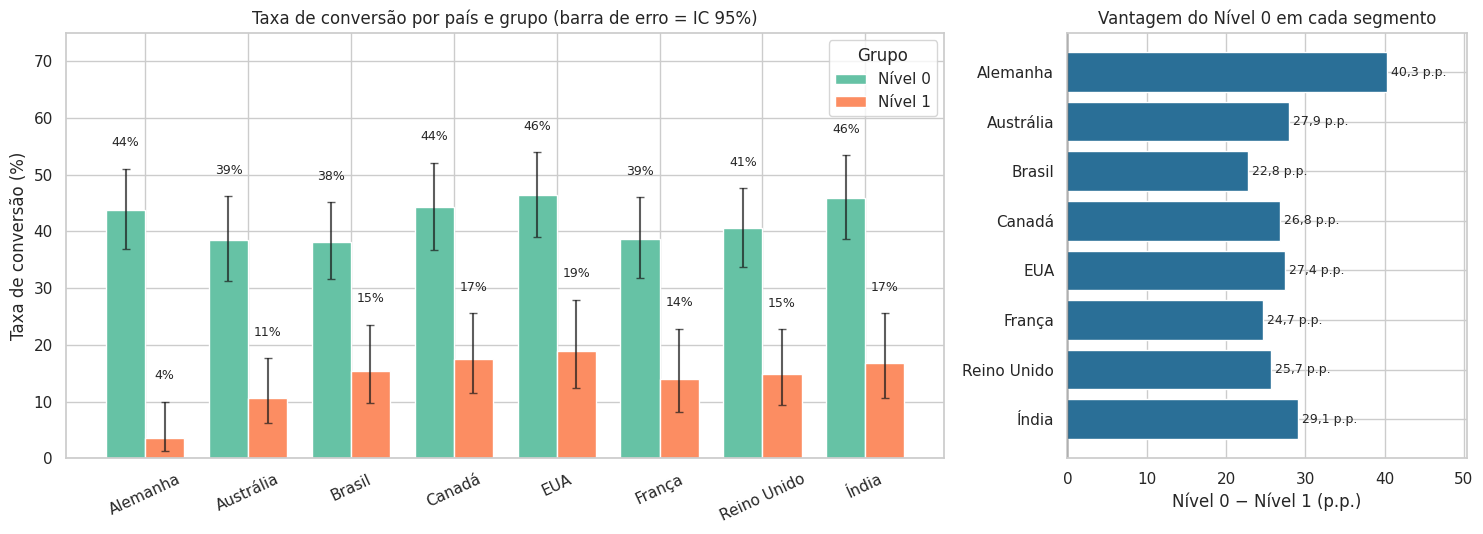

In [ ]:
print('--- Análise por país ---')
tabela_paises, testes_pais = analisar_por_segmento(base_sem_duplicatas, 'country')
display(formatar_colunas_p_valor(tabela_paises.round(2), ['p_Fisher']))
imprimir_p_valores(testes_pais)
pais_critico = avaliar_segmento_critico(base_sem_duplicatas, tabela_paises, 'country')
plotar_conversao_por_segmento(base_sem_duplicatas, tabela_paises, 'country', 'país')

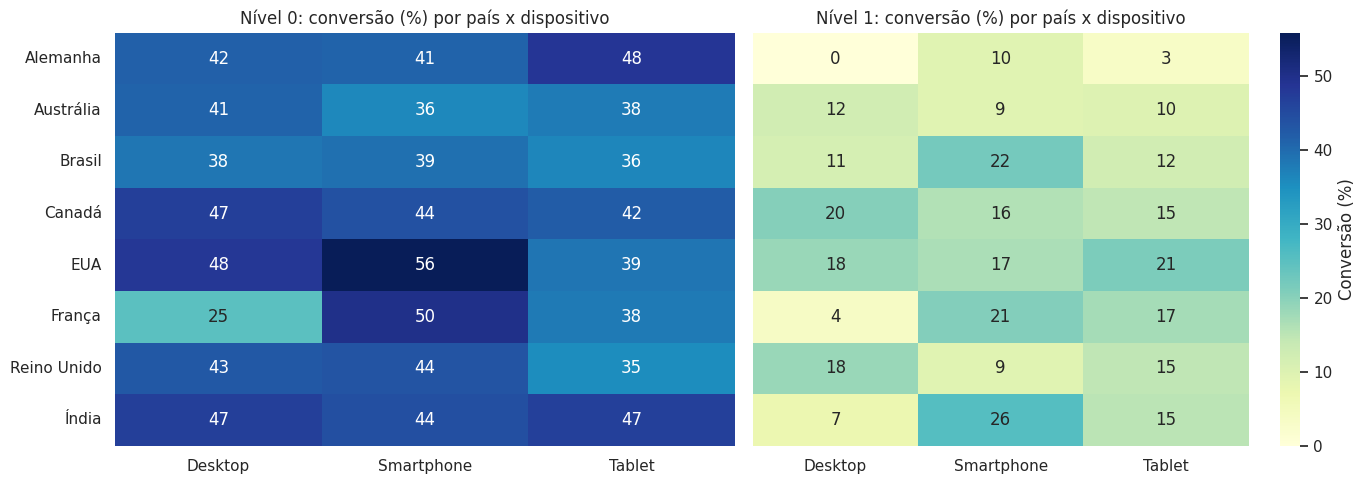

In [ ]:
def plotar_mapa_calor_pais_dispositivo(base: pd.DataFrame):
    """Mapa de calor: conversão (%) por país x dispositivo, um painel por grupo (mesma escala de cor)."""
    figura, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    vmax = base.groupby(['group', 'country', 'device'])['converted'].mean().max() * 100
    for eixo, grupo in zip(eixos, (GRUPO_NIVEL_0, GRUPO_NIVEL_1)):
        tabela = (base[base['group'] == grupo].pivot_table(index='country', columns='device',
                                                           values='converted', aggfunc='mean') * 100)
        sns.heatmap(tabela, annot=True, fmt='.0f', cmap='YlGnBu', vmin=0, vmax=vmax, ax=eixo,
                    cbar=eixo is eixos[-1], cbar_kws={'label': 'Conversão (%)'})
        eixo.set_title(f'{grupo}: conversão (%) por país x dispositivo')
        eixo.set_xlabel('')
        eixo.set_ylabel('')
    plt.tight_layout()
    plt.show()


plotar_mapa_calor_pais_dispositivo(base_sem_duplicatas)

## 7. Q6 – Existe alguma tendência temporal (comportamento ao longo do dia) nos acessos ou conversões para cada configuração do menu?

In [ ]:
def analisar_tendencia_horaria(base_sem_duplicatas: pd.DataFrame):
    """
    Q6: acessos e conversão por hora. A base cobre um único dia, então o padrão pode ser
    específico dele. Testes: a conversão varia por hora? o volume por hora é uniforme?
    """
    base_horas_grupo = base_sem_duplicatas.groupby(['hour', 'group']).agg(
        Acessos=('user_id', 'size'), Conversoes=('converted', 'sum')).reset_index()
    base_horas_grupo['Taxa_Pct'] = base_horas_grupo['Conversoes'] / base_horas_grupo['Acessos'] * 100
    ic_wilson = proportion_confint(base_horas_grupo['Conversoes'], base_horas_grupo['Acessos'], method='wilson')
    base_horas_grupo['IC95_inf'] = ic_wilson[0] * 100
    base_horas_grupo['IC95_sup'] = ic_wilson[1] * 100

    resultados_testes = {}
    for grupo in (GRUPO_NIVEL_0, GRUPO_NIVEL_1):
        base_grupo = base_sem_duplicatas[base_sem_duplicatas['group'] == grupo]
        resultados_testes[f'p_conversao_varia_por_hora_{grupo}'] = chi2_contingency(
            pd.crosstab(base_grupo['hour'], base_grupo['converted']))[1]
        acessos_por_hora = base_grupo['hour'].value_counts().reindex(range(24), fill_value=0)
        resultados_testes[f'p_volume_uniforme_{grupo}'] = stats.chisquare(acessos_por_hora)[1]
    return base_horas_grupo, resultados_testes

In [ ]:
print('--- Q6: Existe alguma tendência temporal (comportamento ao longo dia) nos acessos ou conversões para cada configuração do menu? ---')
base_horas_grupo, testes_hora = analisar_tendencia_horaria(base_sem_duplicatas)
display(base_horas_grupo.pivot(index='hour', columns='group', values=['Acessos', 'Taxa_Pct']).round(1))
imprimir_p_valores(testes_hora)

--- Q6: Existe alguma tendência temporal (comportamento ao longo dia) nos acessos ou conversões para cada configuração do menu? ---


Acessos         Taxa_Pct        
group Nível 0 Nível 1  Nível 0 Nível 1
hour                                  
0        48.0    27.0     33.3     7.4
1        48.0    25.0     22.9    20.0
2        47.0    42.0     36.2    14.3
3        57.0    34.0     28.1     2.9
4        44.0    40.0     31.8     7.5
5        41.0    30.0     36.6    16.7
6        57.0    28.0     31.6     7.1
7        51.0    36.0     25.5    13.9
8        71.0    44.0     57.7    22.7
9        70.0    29.0     60.0     6.9
10       68.0    41.0     41.2    26.8
11       83.0    27.0     67.5    22.2
12       56.0    28.0     51.8    10.7
13       64.0    33.0     60.9     9.1
14       89.0    30.0     44.9    10.0
15       88.0    34.0     43.2    17.6
16       53.0    38.0     37.7    23.7
17       42.0    34.0     47.6    14.7
18       67.0    33.0     32.8    21.2
19       45.0    31.0     33.3     9.7
20       73.0    25.0     34.2    16.0
21       51.0    37.0     35.3    16.2
22       48.0    38.0     41.7     5.3
23       41.0    30.0     36.6    10.0

  p_conversao_varia_por_hora_Nível 0: p < 0,001
  p_volume_uniforme_Nível 0: p < 0,001
  p_conversao_varia_por_hora_Nível 1: p 0,201
  p_volume_uniforme_Nível 1: p 0,590


In [ ]:
def plotar_tendencias_temporais(base_horas_grupo: pd.DataFrame):
    """Q6 (visual): acessos e conversão por hora. A faixa mostra o IC 95%: faixas largas = pouco dado."""
    figura, (eixo_acessos, eixo_conversao) = plt.subplots(2, 1, figsize=(12, 10))
    for grupo in (GRUPO_NIVEL_0, GRUPO_NIVEL_1):
        base_grupo = base_horas_grupo[base_horas_grupo['group'] == grupo]
        cor_grupo = PALETA_CORES_POR_GRUPO[grupo]
        eixo_acessos.plot(base_grupo['hour'], base_grupo['Acessos'], marker='o', label=grupo, color=cor_grupo)
        eixo_conversao.plot(base_grupo['hour'], base_grupo['Taxa_Pct'], marker='o', label=grupo, color=cor_grupo)
        eixo_conversao.fill_between(base_grupo['hour'], base_grupo['IC95_inf'], base_grupo['IC95_sup'],
                                    color=cor_grupo, alpha=0.15)
    eixo_acessos.set_title('Acessos por hora do dia (base sem duplicatas, 1 dia de dados)')
    eixo_acessos.set_ylabel('Quantidade de acessos')
    eixo_conversao.set_title('Taxa de conversão por hora (%) com IC 95%')
    eixo_conversao.set_ylabel('Taxa de conversão (%)')
    for eixo in (eixo_acessos, eixo_conversao):
        eixo.set_xlabel('Hora do dia (0-23)')
        eixo.set_xticks(range(24))
        eixo.grid(axis='y', linestyle='--', alpha=0.7)
        eixo.legend(title='Grupo')
    plt.tight_layout()
    plt.show()

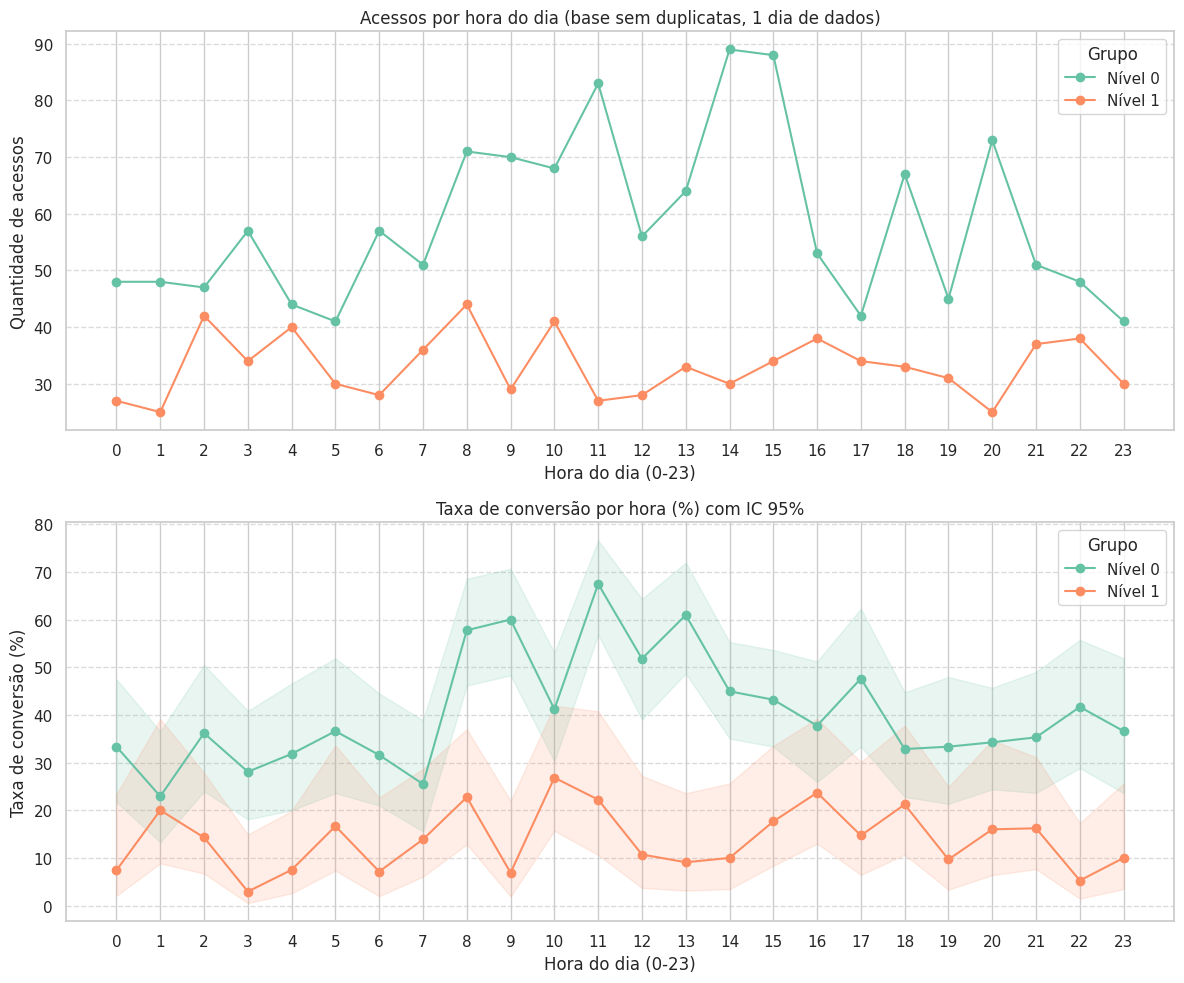

In [ ]:
plotar_tendencias_temporais(base_horas_grupo)

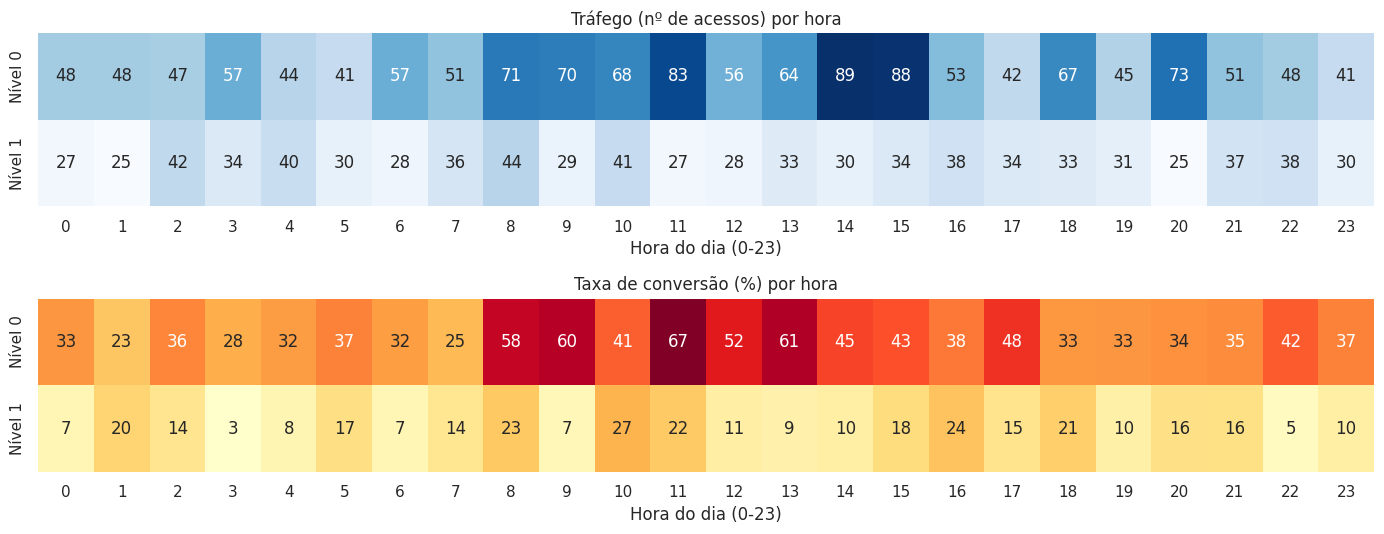

In [ ]:
def plotar_mapa_calor_horas(base_horas_grupo: pd.DataFrame):
    """Mapa de calor hora x grupo: tráfego e conversão lado a lado, para enxergar o contraste manhã x tarde."""
    figura, (eixo_trafego, eixo_conversao) = plt.subplots(2, 1, figsize=(14, 5.5))
    trafego = base_horas_grupo.pivot(index='group', columns='hour', values='Acessos')
    conversao = base_horas_grupo.pivot(index='group', columns='hour', values='Taxa_Pct')
    sns.heatmap(trafego, annot=True, fmt='.0f', cmap='Blues', ax=eixo_trafego, cbar=False)
    eixo_trafego.set_title('Tráfego (nº de acessos) por hora')
    sns.heatmap(conversao, annot=True, fmt='.0f', cmap='YlOrRd', ax=eixo_conversao, cbar=False)
    eixo_conversao.set_title('Taxa de conversão (%) por hora')
    for eixo in (eixo_trafego, eixo_conversao):
        eixo.set_xlabel('Hora do dia (0-23)')
        eixo.set_ylabel('')
    plt.tight_layout()
    plt.show()


plotar_mapa_calor_horas(base_horas_grupo)

### Resposta (Q6)

Existe uma tendência temporal. Como mostra a imagem gerada pelo código, há um pico de acessos no início da tarde, das 14h às 15h, no tráfego do Nível 0. Porém, nesse mesmo período, a taxa de conversão cai para cerca de 44%. Por outro lado, durante a manhã, entre 8h e 11h, a quantidade de acessos e a conversão aumentam simultaneamente, o que sugere que esse seja o horário de maior propensão à conversão dos usuários. Nesse intervalo, há um alto volume de acessos acompanhado das maiores taxas de conversão, com picos próximos de 60% e 67%. O Nível 0 converte mais que o Nível 1 em todas as horas. Como os dados cobrem apenas 1 dia e o fuso horário é desconhecido, os horários devem ser tratados como hipótese a validar.

## 8. Q5 – Quais insights podem ser derivados dos dados para otimizar a navegação do site e aumentar o engajamento dos usuários?

### Resposta (Q5)

[1] O que os dados mostram
- Conversão (acesso à página): Nível 0 = 41,9% vs Nível 1 = 14,1%. Diferença de 27,8 p.p. (IC 95%: 24,3 a 31,4), odds ratio 4,40, p < 0,001.
- A diferença é significativa em 4 dos 4 cenários testados (base bruta, sem duplicatas, 1ª visita de cada id, só ids de um grupo; entre 24,8 e 28,2 p.p.) e após ajuste por hora, dispositivo e país (odds ratio ajustado = 4,46, bruto = 4,40).
- Não chegaram à página: 86,3% no Nível 1 vs 58,9% no Nível 0. É o complemento da conversão, não uma métrica independente. Duração zero significa 'não chegou à página' e não 'saiu do site'.
- Tempo na página: entre quem chegou, 19,1s (Nível 0) vs 11,2s (Nível 1). Por acesso, incluindo quem não chegou, 7,87s vs 1,54s (dif. 6,33s; p Mann-Whitney < 0,001). A visão 'quem chegou' compara públicos selecionados: use-a com cautela.
- Consistência: Nível 0 convertendo mais em 8 de 8 países e em 3 de 3 dispositivos.
- Dispositivo: não há evidência de diferença relevante (entre dispositivos: p 0,498 no Nível 0 e 0,374 no Nível 1; interação grupo x dispositivo: p 0,748).

- A taxa de acesso à página no Nível 0 é 3,0 vezes(41,94 / 14,11 = 2,972) a do Nível 1 (+197%), sendo a escolha correta para seguir após o teste ab. Entretanto, embora o Nível 0 seja o vencedor, como recomendação sugiro incluir a manutenção do teste por mais dias, porque os dados refletem apenas 1 dia de coleta, com um fuso horário desconhecido, o que invalida qualquer otimização focada em horários específicos.Além disso, a alocação de usuários no teste A/B demonstrou uma falha do tráfego não foi dividido 50/50.

## 9. Q7 – Quais recomendações você faria com base nos dados analisados para otimizar a navegação do site?

### Resposta (Q7)

1. Adotar o Nível 0, com confirmação: a direção é clara, mas a decisão de 100% da base deve esperar mais dias de teste e a explicação da alocação desigual.
2. Auditar o tracking: 109 linhas duplicadas (4,7% da base; 100% eram conversões, o que pode sugerir um evento de conversão disparado duas vezes) e 23 conversões únicas sem duração medida, vinheram com null.
3. Auditar a alocação: como o user_id é gerado, se a atribuição é por usuário ou por sessão, por que 63,8% do tráfego caiu no Nível 0 e por que o volume por hora difere entre os grupos (p do balanceamento por hora 0,003).
4. Focar em no periodo da manha para tentar adquirir mais acessos, mas ter um novo o monitoramento do Nível 0 por mais dias para confirmar a tendência temporal (o pico de conversão entre 8h e 11h) e validar o horário como um padrão confirmar o fuso horário e se a tendência se confirmar em uma janela de dados maior, sugerir a atividade de sincronizar notificações push, campanhas de e-mail com esse horário, campanha de marketing no horário de pico.

## 10. Exportação da base para o Power BI

A base é exportada **sem duplicatas exatas** e **mantendo** os convertidos sem duração (nulos): são conversões reais, e o `AVERAGE` do Power BI ignora nulos nas médias de tempo.

In [ ]:
def exportar_base_limpa(base_sem_duplicatas: pd.DataFrame, nome_arquivo_saida: Path = ARQUIVO_SAIDA):
    """
    Exporta a base tratada para Excel (uso no Power BI): sem duplicatas exatas.
    Mantém os convertidos sem duração (nulos);
    """
    base_para_exportacao = base_sem_duplicatas.copy()
    base_para_exportacao.to_excel(nome_arquivo_saida, index=False, sheet_name='ab_data')
    print(f"\n[!] Base exportada com sucesso para '{nome_arquivo_saida}' (Tamanho: {len(base_para_exportacao)} linhas).")

In [ ]:
exportar_base_limpa(base_sem_duplicatas)


[!] Base exportada com sucesso para '/home/claude/proj/ab_test_data_sem_duplicatas.xlsx' (Tamanho: 2196 linhas).
